# Jar Growth Intern Assignment
## Q1 — Part 1: Sales & Profitability Analysis

## 1. Objective

Determine how the three product categories (Electronics, Clothing, Furniture) perform in terms of **sales** and **profitability**, and why they differ.

For each category the analysis calculates:

- **Total sales** (sum of `Amount`)
- **Average profit per order** (see methodology in Section 7)
- **Total profit** and **profit margin** = Total Profit / Total Sales × 100

Sub-categories are then examined to explain what drives the category-level differences. All figures are calculated in Python from the two source tables; nothing is hard-coded.

## 2. Import Libraries

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style='whitegrid', context='notebook')
pd.options.display.float_format = '{:,.2f}'.format

CATEGORY_COLORS = {'Electronics': '#1f4e79', 'Clothing': '#2e8b57', 'Furniture': '#c0642b'}
rupee = lambda x: f"₹{x:,.0f}" if x >= 0 else f"-₹{abs(x):,.0f}"
rupee2 = lambda x: f'₹{x:,.2f}' if x >= 0 else f'-₹{abs(x):,.2f}'

## 3. Load Data

The analysis loads the two processed source tables and performs the merge itself. `merged_order_data.csv` is **not** used as an input; it is only used for an optional cross-check after the merge.

In [2]:
DATA_DIR = Path('../data/processed')

orders = pd.read_csv(DATA_DIR / 'list_of_orders.csv')
details = pd.read_csv(DATA_DIR / 'order_details.csv')

display(orders.head())
display(details.head())

,Order ID,Order Date,CustomerName,State,City
0,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad
1,B-25602,2018-04-01,Pearl,Maharashtra,Pune
2,B-25603,2018-04-03,Jahan,Madhya Pradesh,Bhopal
3,B-25604,2018-04-03,Divsha,Rajasthan,Jaipur
4,B-25605,2018-04-05,Kasheen,West Bengal,Kolkata


,Order ID,Amount,Profit,Quantity,Category,Sub-Category
0,B-25601,1275,-1148,7,Furniture,Bookcases
1,B-25601,66,-12,5,Clothing,Stole
2,B-25601,8,-2,3,Clothing,Hankerchief
3,B-25601,80,-56,4,Electronics,Electronic Games
4,B-25602,168,-111,2,Electronics,Phones


## 4. Data Validation

Checks on each table before merging: size, columns, data types, missing values, unique Order IDs and duplicates.
Duplicate Order IDs are **expected** in Order Details (one order can contain several products) but not in List of Orders.

In [3]:
def validation_summary(df, name):
    return pd.Series({
        'Rows': len(df),
        'Columns': df.shape[1],
        'Unique Order IDs': df['Order ID'].nunique(),
        'Duplicate rows': int(df.duplicated().sum()),
        'Rows sharing an Order ID': int(df['Order ID'].duplicated().sum()),
        'Missing values (total)': int(df.isna().sum().sum()),
    }, name=name)

display(pd.concat([validation_summary(orders, 'List of Orders'),
                   validation_summary(details, 'Order Details')], axis=1))

for name, df in [('List of Orders', orders), ('Order Details', details)]:
    print(f"\n{name} — columns, data types and missing values")
    display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum()}))

,List of Orders,Order Details
Rows,500,1500
Columns,5,6
Unique Order IDs,500,500
Duplicate rows,0,0
Rows sharing an Order ID,0,1000
Missing values (total),0,0



List of Orders — columns, data types and missing values


,dtype,missing
Order ID,str,0
Order Date,str,0
CustomerName,str,0
State,str,0
City,str,0



Order Details — columns, data types and missing values


,dtype,missing
Order ID,str,0
Amount,int64,0
Profit,int64,0
Quantity,int64,0
Category,str,0
Sub-Category,str,0


## 5. Merge Datasets

List of Orders (one row per order) is merged with Order Details (one or more rows per order) on `Order ID`. The merge is declared `one_to_many`, so pandas raises an error if Order ID were duplicated in List of Orders. An outer merge with an indicator is used so that any unmatched Order ID would be visible.

In [4]:
EXPECTED_ROWS, EXPECTED_ORDERS = 1500, 500   # dataset sizes given in the assignment brief

merged = orders.merge(details, on='Order ID', how='outer', validate='one_to_many', indicator=True)

checks = pd.DataFrame([
    ('Merged row count', EXPECTED_ROWS, len(merged)),
    ('Unique Order IDs', EXPECTED_ORDERS, merged['Order ID'].nunique()),
    ('Unmatched Order IDs (in only one table)', 0, int((merged['_merge'] != 'both').sum())),
    ('Missing values after merge', 0, int(merged.drop(columns='_merge').isna().sum().sum())),
], columns=['Check', 'Expected', 'Actual'])
checks['Result'] = np.where(checks['Expected'] == checks['Actual'], 'PASS', 'FAIL')
display(checks.style.hide(axis='index'))

merged = merged.drop(columns='_merge')

Check,Expected,Actual,Result
Merged row count,1500,1500,PASS
Unique Order IDs,500,500,PASS
Unmatched Order IDs (in only one table),0,0,PASS
Missing values after merge,0,0,PASS


In [5]:
# Optional cross-check against the pre-merged file (not used as a source of truth)
merged_csv = DATA_DIR / 'merged_order_data.csv'
if merged_csv.exists():
    pre = pd.read_csv(merged_csv)
    same = (len(pre) == len(merged)
            and np.isclose(pre['Amount'].sum(), merged['Amount'].sum())
            and np.isclose(pre['Profit'].sum(), merged['Profit'].sum()))
    print(f"merged_order_data.csv found: {len(pre):,} rows. Row count, total Amount and total Profit match: {same}")
else:
    print("merged_order_data.csv not found - cross-check skipped.")

merged_order_data.csv found: 1,500 rows. Row count, total Amount and total Profit match: True


## 6. Total Sales by Category

In [6]:
sales_by_category = (merged.groupby('Category')['Amount'].sum()
                     .sort_values(ascending=False).rename('Total Sales').to_frame())
sales_by_category['Share of Sales (%)'] = sales_by_category['Total Sales'] / sales_by_category['Total Sales'].sum() * 100

sales_by_category.style.format({'Total Sales': rupee, 'Share of Sales (%)': '{:.2f}%'})

,Total Sales,Share of Sales (%)
Category,,
Electronics,"₹165,267",38.30%
Clothing,"₹139,054",32.23%
Furniture,"₹127,181",29.47%


## 7. Average Profit per Order

An order can contain several line items of the same category, so averaging line-item profits would not represent profit *per order*. The method used is:

1. Group by **Order ID + Category** and sum `Profit` within each group (profit of one category within one order).
2. Take the **mean** of those order-category totals for each Category.

Average sales per order-category combination is shown alongside for context.

In [7]:
order_category = (merged.groupby(['Order ID', 'Category'], as_index=False)
                  .agg(Profit=('Profit', 'sum'), Sales=('Amount', 'sum')))
display(order_category.head(8).style.format({'Profit': rupee, 'Sales': rupee}).hide(axis='index'))

avg_profit_per_order = (order_category.groupby('Category')
                        .agg(**{'Order-Category Combinations': ('Profit', 'size'),
                                'Average Profit per Order': ('Profit', 'mean'),
                                'Average Sales per Order': ('Sales', 'mean')})
                        .sort_values('Average Profit per Order', ascending=False))

avg_profit_per_order.style.format({'Order-Category Combinations': '{:,.0f}',
                                   'Average Profit per Order': rupee2,
                                   'Average Sales per Order': rupee2})

Order ID,Category,Profit,Sales
B-25601,Clothing,-₹14,₹74
B-25601,Electronics,-₹56,₹80
B-25601,Furniture,"-₹1,148","₹1,275"
B-25602,Clothing,₹207,₹680
B-25602,Electronics,₹768,"₹3,209"
B-25603,Clothing,-₹150,"₹2,001"
B-25603,Furniture,-₹30,₹24
B-25604,Clothing,₹22,₹222


,Order-Category Combinations,Average Profit per Order,Average Sales per Order
Category,,,
Electronics,204,₹51.44,₹810.13
Clothing,393,₹28.40,₹353.83
Furniture,186,₹12.35,₹683.77


## 8. Profit Margin by Category

**Profit Margin = Total Profit / Total Sales × 100**, computed from category totals (not as an average of row-level percentages).

In [8]:
summary = (merged.groupby('Category')
           .agg(**{'Total Sales': ('Amount', 'sum'), 'Total Profit': ('Profit', 'sum')}))
summary['Profit Margin (%)'] = summary['Total Profit'] / summary['Total Sales'] * 100
summary = (summary.join(avg_profit_per_order['Average Profit per Order'])
                  .sort_values('Total Sales', ascending=False))

overall_sales, overall_profit = summary['Total Sales'].sum(), summary['Total Profit'].sum()
overall_margin = overall_profit / overall_sales * 100

display(summary.style.format({'Total Sales': rupee, 'Total Profit': rupee,
                              'Profit Margin (%)': '{:.2f}%', 'Average Profit per Order': rupee2}))
print(f"All categories combined: sales {rupee(overall_sales)}, profit {rupee(overall_profit)}, margin {overall_margin:.2f}%")

,Total Sales,Total Profit,Profit Margin (%),Average Profit per Order
Category,,,,
Electronics,"₹165,267","₹10,494",6.35%,₹51.44
Clothing,"₹139,054","₹11,163",8.03%,₹28.40
Furniture,"₹127,181","₹2,298",1.81%,₹12.35


All categories combined: sales ₹431,502, profit ₹23,955, margin 5.55%


## 9. Visualizations

/var/folders/mm/93chsfl55kvcrzyvg13_c7mh0000gn/T/ipykernel_34293/14917411.py:19: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/ankitalokhande/Desktop/nexora/Q1_Sales_Analysis/Part_1_Sales_Profitability/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


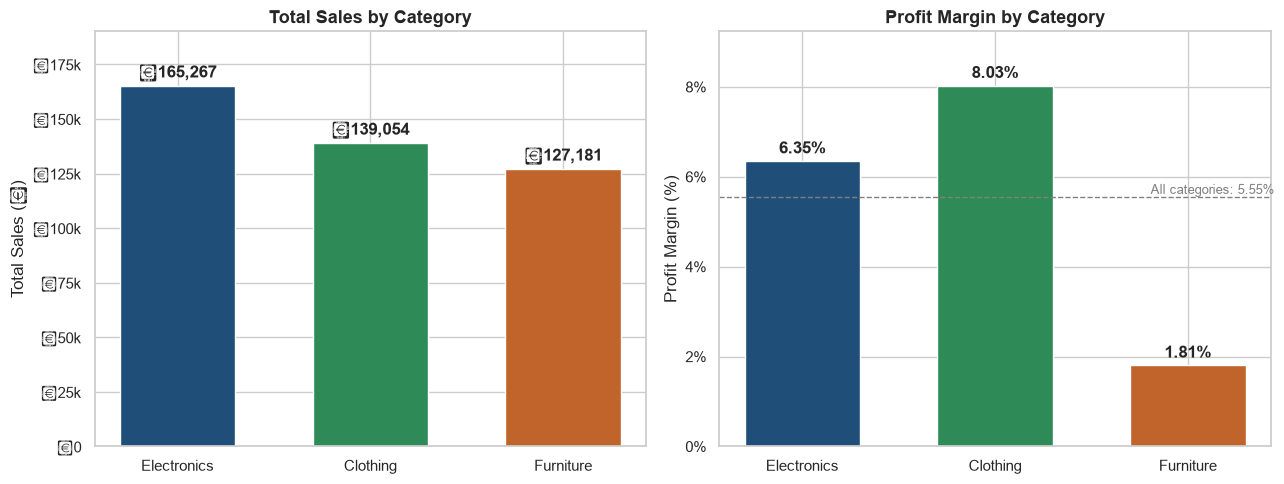

In [9]:
def category_bar(ax, series, title, fmt, ylabel, zero_line=False):
    colors = [CATEGORY_COLORS.get(c, 'grey') for c in series.index]
    bars = ax.bar(series.index, series.values, color=colors, width=0.6)
    ax.bar_label(bars, labels=[fmt(v) for v in series.values], padding=3, fontweight='bold')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.set_xlabel('')
    ax.margins(y=0.15)
    if zero_line:
        ax.axhline(0, color='black', linewidth=0.8)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
category_bar(axes[0], summary['Total Sales'], 'Total Sales by Category', rupee, 'Total Sales (₹)')
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: "₹0" if x == 0 else f"₹{x/1000:,.0f}k"))
category_bar(axes[1], summary['Profit Margin (%)'], 'Profit Margin by Category', lambda v: f"{v:.2f}%", 'Profit Margin (%)')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[1].axhline(overall_margin, color='grey', linestyle='--', linewidth=1)
axes[1].text(2.45, overall_margin, f" All categories: {overall_margin:.2f}%", va='bottom', ha='right', color='grey', fontsize=9)
plt.tight_layout()
plt.show()

/var/folders/mm/93chsfl55kvcrzyvg13_c7mh0000gn/T/ipykernel_34293/1491911844.py:5: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()


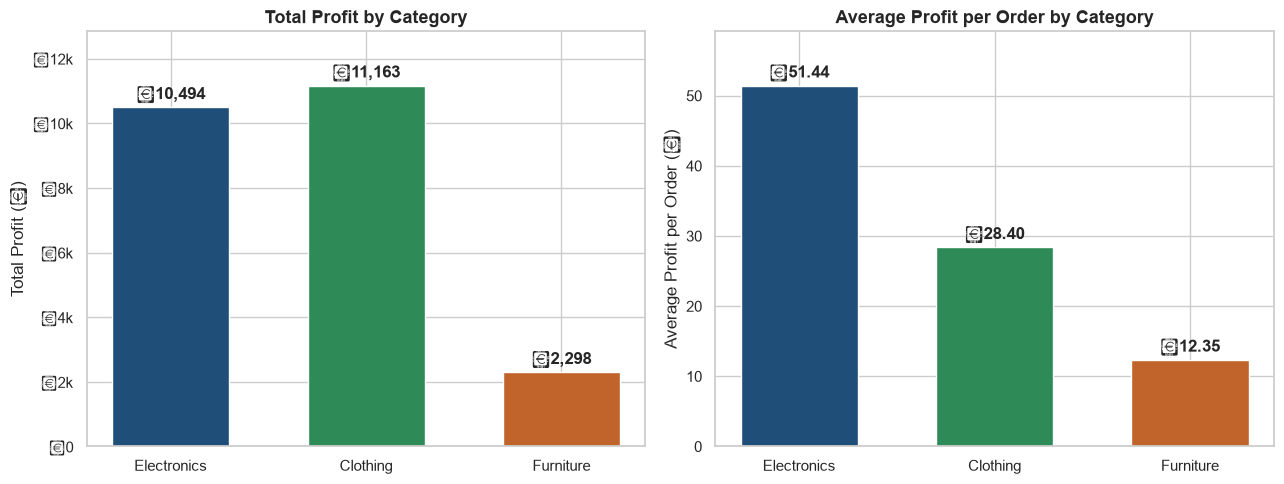

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
category_bar(axes[0], summary['Total Profit'], 'Total Profit by Category', rupee, 'Total Profit (₹)')
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: "₹0" if x == 0 else f"₹{x/1000:,.0f}k"))
category_bar(axes[1], summary['Average Profit per Order'], 'Average Profit per Order by Category', rupee2, 'Average Profit per Order (₹)')
plt.tight_layout()
plt.show()

The charts show that the category with the highest sales is not the same as the category with the highest margin. The sub-category analysis below looks at why.

## 10. Sub-Category Analysis

Sales, profit and margin by sub-category (margin = sub-category profit / sub-category sales × 100). Three groups are flagged using rules that are applied to the data:

- **Loss-making**: total profit below zero.
- **High-margin**: margin in the top quartile of all sub-categories.
- **High sales, low profit**: total sales at or above the median sub-category *and* margin below the all-category margin.

In [11]:
sub = (merged.groupby(['Category', 'Sub-Category'])
       .agg(**{'Line Items': ('Amount', 'size'), 'Total Sales': ('Amount', 'sum'), 'Total Profit': ('Profit', 'sum')})
       .reset_index())
sub['Profit Margin (%)'] = sub['Total Profit'] / sub['Total Sales'] * 100
sub['Share of Category Sales (%)'] = sub['Total Sales'] / sub.groupby('Category')['Total Sales'].transform('sum') * 100

sub['Category'] = pd.Categorical(sub['Category'], categories=summary.index, ordered=True)
sub = sub.sort_values(['Category', 'Total Sales'], ascending=[True, False]).reset_index(drop=True)

sub_fmt = {'Line Items': '{:,.0f}', 'Total Sales': rupee, 'Total Profit': rupee,
           'Profit Margin (%)': '{:.2f}%', 'Share of Category Sales (%)': '{:.1f}%'}
sub.style.format(sub_fmt).hide(axis='index')

Category,Sub-Category,Line Items,Total Sales,Total Profit,Profit Margin (%),Share of Category Sales (%)
Electronics,Printers,74,"₹58,252","₹5,964",10.24%,35.2%
Electronics,Phones,83,"₹46,119","₹2,207",4.79%,27.9%
Electronics,Electronic Games,79,"₹39,168","-₹1,236",-3.16%,23.7%
Electronics,Accessories,72,"₹21,728","₹3,559",16.38%,13.1%
Clothing,Saree,210,"₹53,511",₹352,0.66%,38.5%
Clothing,Trousers,39,"₹30,039","₹2,847",9.48%,21.6%
Clothing,Stole,192,"₹18,546","₹2,559",13.80%,13.3%
Clothing,Hankerchief,198,"₹14,608","₹2,098",14.36%,10.5%
Clothing,Shirt,69,"₹7,555","₹1,131",14.97%,5.4%
Clothing,T-shirt,77,"₹7,382","₹1,500",20.32%,5.3%


In [12]:
median_sales = sub['Total Sales'].median()
high_margin_cutoff = sub['Profit Margin (%)'].quantile(0.75)

loss_making = sub[sub['Total Profit'] < 0].sort_values('Total Profit')
high_margin = sub[sub['Profit Margin (%)'] >= high_margin_cutoff].sort_values('Profit Margin (%)', ascending=False)
high_sales_low_profit = (sub[(sub['Total Sales'] >= median_sales) & (sub['Profit Margin (%)'] < overall_margin)]
                         .sort_values('Total Sales', ascending=False))

print(f"Thresholds: median sub-category sales = {rupee(median_sales)}; top-quartile margin cutoff = {high_margin_cutoff:.2f}%; all-category margin = {overall_margin:.2f}%")
for title, frame in [('Loss-making sub-categories', loss_making),
                     ('High-margin sub-categories', high_margin),
                     ('High-sales, low-profit sub-categories', high_sales_low_profit)]:
    print(f"\n{title}")
    display(frame.drop(columns='Share of Category Sales (%)').style.format(sub_fmt).hide(axis='index'))

Thresholds: median sub-category sales = ₹21,728; top-quartile margin cutoff = 13.80%; all-category margin = 5.55%

Loss-making sub-categories


Category,Sub-Category,Line Items,Total Sales,Total Profit,Profit Margin (%)
Furniture,Tables,17,"₹22,614","-₹4,011",-17.74%
Electronics,Electronic Games,79,"₹39,168","-₹1,236",-3.16%



High-margin sub-categories


Category,Sub-Category,Line Items,Total Sales,Total Profit,Profit Margin (%)
Clothing,T-shirt,77,"₹7,382","₹1,500",20.32%
Electronics,Accessories,72,"₹21,728","₹3,559",16.38%
Clothing,Shirt,69,"₹7,555","₹1,131",14.97%
Clothing,Hankerchief,198,"₹14,608","₹2,098",14.36%
Clothing,Stole,192,"₹18,546","₹2,559",13.80%



High-sales, low-profit sub-categories


Category,Sub-Category,Line Items,Total Sales,Total Profit,Profit Margin (%)
Clothing,Saree,210,"₹53,511",₹352,0.66%
Electronics,Phones,83,"₹46,119","₹2,207",4.79%
Electronics,Electronic Games,79,"₹39,168","-₹1,236",-3.16%
Furniture,Chairs,74,"₹34,222",₹577,1.69%
Furniture,Tables,17,"₹22,614","-₹4,011",-17.74%


### Sub-category charts

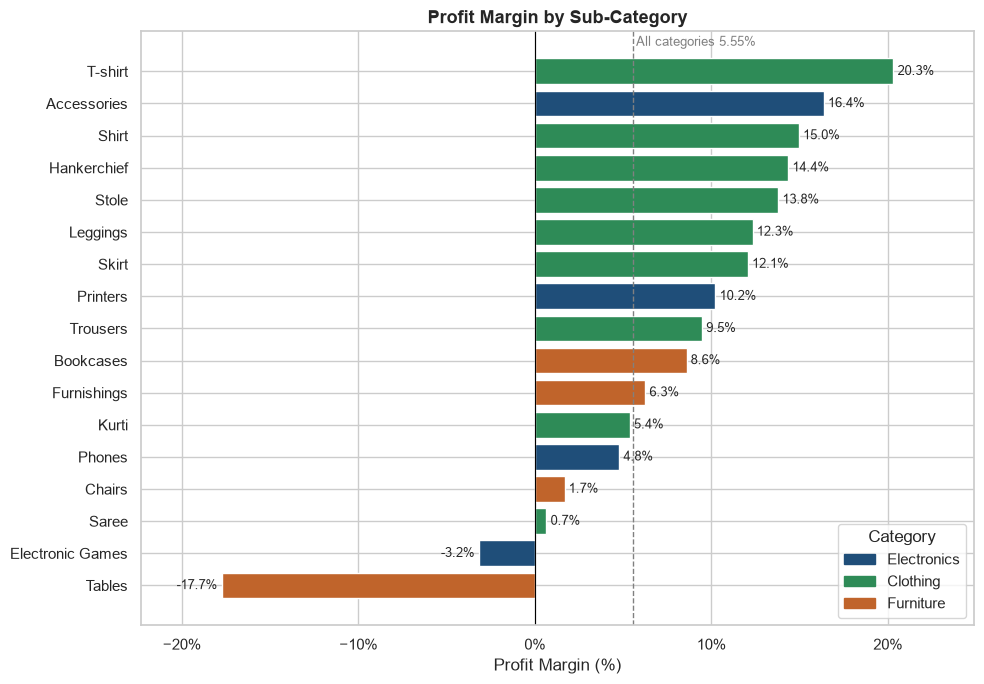

In [13]:
plot_df = sub.sort_values('Profit Margin (%)')
colors = [CATEGORY_COLORS[c] for c in plot_df['Category']]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(plot_df['Sub-Category'], plot_df['Profit Margin (%)'], color=colors)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in plot_df['Profit Margin (%)']], padding=3, fontsize=9)
ax.axvline(0, color='black', linewidth=0.8)
ax.axvline(overall_margin, color='grey', linestyle='--', linewidth=1)
ax.text(overall_margin, len(plot_df) - 0.3, f" All categories {overall_margin:.2f}%", color='grey', fontsize=9, va='bottom')
ax.set_title('Profit Margin by Sub-Category', fontsize=13, fontweight='bold')
ax.set_xlabel('Profit Margin (%)')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.margins(x=0.12)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in CATEGORY_COLORS.values()],
          labels=CATEGORY_COLORS.keys(), loc='lower right', title='Category')
plt.tight_layout()
plt.show()

/var/folders/mm/93chsfl55kvcrzyvg13_c7mh0000gn/T/ipykernel_34293/408083265.py:19: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/ankitalokhande/Desktop/nexora/Q1_Sales_Analysis/Part_1_Sales_Profitability/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


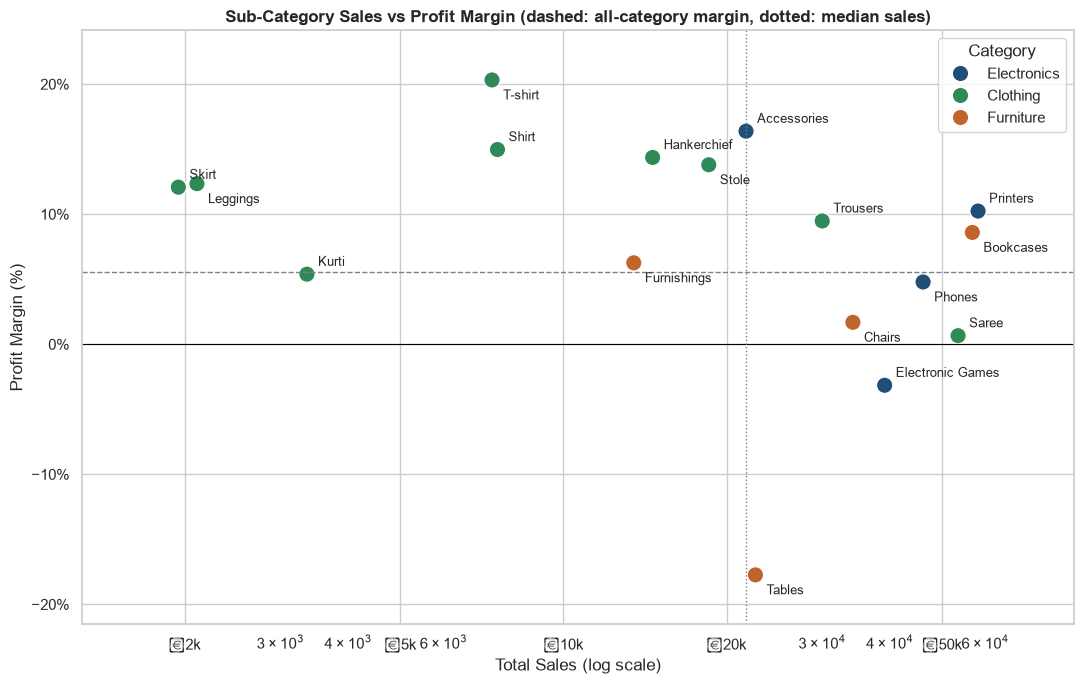

In [14]:
fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=sub, x='Total Sales', y='Profit Margin (%)', hue='Category', palette=CATEGORY_COLORS,
                s=140, edgecolor='white', ax=ax)
ax.set_xscale('log')
ax.set_xticks([2000, 5000, 10000, 20000, 50000])
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: "₹0" if x == 0 else f"₹{x/1000:,.0f}k"))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.axhline(0, color='black', linewidth=0.8)
ax.axhline(overall_margin, color='grey', linestyle='--', linewidth=1)
ax.axvline(median_sales, color='grey', linestyle=':', linewidth=1)

offsets = [(8, 6), (8, -14)]
for i, row in enumerate(sub.sort_values('Total Sales').itertuples()):
    ax.annotate(row[2], (row[4], row[6]), xytext=offsets[i % 2], textcoords='offset points', fontsize=9)

ax.set_title('Sub-Category Sales vs Profit Margin (dashed: all-category margin, dotted: median sales)', fontsize=12, fontweight='bold')
ax.set_xlabel('Total Sales (log scale)')
ax.margins(x=0.12, y=0.1)
plt.tight_layout()
plt.show()

### Effect of loss-making sub-categories on category results

The table below recalculates each category's profit and margin with its loss-making sub-categories removed. This is an illustration of how much those sub-categories weigh on the category result, not a recommendation to stop selling them.

In [15]:
loss_by_cat = loss_making.groupby('Category', observed=True).agg(
    **{'Loss-making sub-categories': ('Sub-Category', lambda s: ', '.join(s)),
       'Their Sales': ('Total Sales', 'sum'), 'Their Profit': ('Total Profit', 'sum')})

impact = summary[['Total Sales', 'Total Profit', 'Profit Margin (%)']].join(loss_by_cat)
impact[['Their Sales', 'Their Profit']] = impact[['Their Sales', 'Their Profit']].fillna(0)
impact['Loss-making sub-categories'] = impact['Loss-making sub-categories'].fillna('None')
impact['Profit excl. them'] = impact['Total Profit'] - impact['Their Profit']
impact['Margin excl. them (%)'] = impact['Profit excl. them'] / (impact['Total Sales'] - impact['Their Sales']) * 100

impact.style.format({'Total Sales': rupee, 'Total Profit': rupee, 'Profit Margin (%)': '{:.2f}%',
                     'Their Sales': rupee, 'Their Profit': rupee, 'Profit excl. them': rupee,
                     'Margin excl. them (%)': '{:.2f}%'})

,Total Sales,Total Profit,Profit Margin (%),Loss-making sub-categories,Their Sales,Their Profit,Profit excl. them,Margin excl. them (%)
Category,,,,,,,,
Electronics,"₹165,267","₹10,494",6.35%,Electronic Games,"₹39,168","-₹1,236","₹11,730",9.30%
Clothing,"₹139,054","₹11,163",8.03%,None,₹0,₹0,"₹11,163",8.03%
Furniture,"₹127,181","₹2,298",1.81%,Tables,"₹22,614","-₹4,011","₹6,309",6.03%


## 11. Top vs Underperforming Categories

Categories are ranked on each of the four metrics (1 = best).

In [16]:
metrics = ['Total Sales', 'Total Profit', 'Profit Margin (%)', 'Average Profit per Order']
ranks = summary[metrics].rank(ascending=False).astype(int)
ranks['Average Rank'] = ranks.mean(axis=1)
display(ranks.sort_values('Average Rank').style.format({'Average Rank': '{:.2f}'}))

lines = []
for m in metrics:
    lines.append(f"- **{m}**: highest = {summary[m].idxmax()}, lowest = {summary[m].idxmin()}")
weakest = ranks['Average Rank'].idxmax()
last_on = [m for m in metrics if ranks.loc[weakest, m] == len(ranks)]
lines.append(f"\n**Weakest category overall: {weakest}** (ranked last on {len(last_on)} of {len(metrics)} metrics).")
display(Markdown('\n'.join(lines)))

,Total Sales,Total Profit,Profit Margin (%),Average Profit per Order,Average Rank
Category,,,,,
Electronics,1,2,2,1,1.50
Clothing,2,1,1,2,1.50
Furniture,3,3,3,3,3.00


- **Total Sales**: highest = Electronics, lowest = Furniture
- **Total Profit**: highest = Clothing, lowest = Furniture
- **Profit Margin (%)**: highest = Clothing, lowest = Furniture
- **Average Profit per Order**: highest = Electronics, lowest = Furniture

**Weakest category overall: Furniture** (ranked last on 4 of 4 metrics).

### Exceptions within each category

In [17]:
exceptions = []
for cat, grp in sub.groupby('Category', observed=True):
    best, worst = grp.loc[grp['Profit Margin (%)'].idxmax()], grp.loc[grp['Profit Margin (%)'].idxmin()]
    exceptions.append({
        'Category': cat,
        'Category margin': summary.loc[cat, 'Profit Margin (%)'],
        'Highest-margin sub-category': f"{best['Sub-Category']} ({best['Profit Margin (%)']:.2f}%)",
        'Lowest-margin sub-category': f"{worst['Sub-Category']} ({worst['Profit Margin (%)']:.2f}%)",
        'Loss-making': ', '.join(grp.loc[grp['Total Profit'] < 0, 'Sub-Category']) or 'None',
        'Largest profit contributor': grp.loc[grp['Total Profit'].idxmax(), 'Sub-Category'],
    })
display(pd.DataFrame(exceptions).style.format({'Category margin': '{:.2f}%'}).hide(axis='index'))

Category,Category margin,Highest-margin sub-category,Lowest-margin sub-category,Loss-making,Largest profit contributor
Electronics,6.35%,Accessories (16.38%),Electronic Games (-3.16%),Electronic Games,Printers
Clothing,8.03%,T-shirt (20.32%),Saree (0.66%),None,Trousers
Furniture,1.81%,Bookcases (8.60%),Tables (-17.74%),Tables,Bookcases


## 12. Business Insights

The statements below are generated from the calculated results. The first table shows that high sales do not line up with high profitability at sub-category level.

In [18]:
rank_df = sub[['Category', 'Sub-Category', 'Total Sales', 'Profit Margin (%)']].copy()
rank_df['Sales Rank'] = rank_df['Total Sales'].rank(ascending=False).astype(int)
rank_df['Margin Rank'] = rank_df['Profit Margin (%)'].rank(ascending=False).astype(int)
rank_df = rank_df.sort_values('Sales Rank')
display(rank_df.style.format({'Total Sales': rupee, 'Profit Margin (%)': '{:.2f}%'}).hide(axis='index'))

corr = sub['Total Sales'].corr(sub['Profit Margin (%)'])
print(f"Correlation between sub-category sales and profit margin: {corr:.2f} (n = {len(sub)})")

Category,Sub-Category,Total Sales,Profit Margin (%),Sales Rank,Margin Rank
Electronics,Printers,"₹58,252",10.24%,1,8
Furniture,Bookcases,"₹56,861",8.60%,2,10
Clothing,Saree,"₹53,511",0.66%,3,15
Electronics,Phones,"₹46,119",4.79%,4,13
Electronics,Electronic Games,"₹39,168",-3.16%,5,16
Furniture,Chairs,"₹34,222",1.69%,6,14
Clothing,Trousers,"₹30,039",9.48%,7,9
Furniture,Tables,"₹22,614",-17.74%,8,17
Electronics,Accessories,"₹21,728",16.38%,9,2
Clothing,Stole,"₹18,546",13.80%,10,5


Correlation between sub-category sales and profit margin: -0.33 (n = 17)


In [19]:
top_sales_cat = summary['Total Sales'].idxmax()
top_margin_cat = summary['Profit Margin (%)'].idxmax()
top_profit_cat = summary['Total Profit'].idxmax()
top_avg_cat = summary['Average Profit per Order'].idxmax()
s = summary

# the largest-selling sub-category that still earns a (very low) positive margin
low_margin_big = high_sales_low_profit[high_sales_low_profit['Total Profit'] >= 0].sort_values('Profit Margin (%)')

pts = []
pts.append(f"**{top_sales_cat}** has the highest total sales ({rupee(s.loc[top_sales_cat, 'Total Sales'])}, {sales_by_category.loc[top_sales_cat, 'Share of Sales (%)']:.1f}% of all sales)"
           + (f" and also the highest average profit per order ({rupee2(s.loc[top_avg_cat, 'Average Profit per Order'])})." if top_avg_cat == top_sales_cat
              else f". The highest average profit per order is in **{top_avg_cat}** ({rupee2(s.loc[top_avg_cat, 'Average Profit per Order'])})."))
pts.append(f"**{top_margin_cat}** has the highest profit margin ({s.loc[top_margin_cat, 'Profit Margin (%)']:.2f}%)"
           + (f" and the highest total profit ({rupee(s.loc[top_profit_cat, 'Total Profit'])})" if top_profit_cat == top_margin_cat
              else f", while the highest total profit is in **{top_profit_cat}** ({rupee(s.loc[top_profit_cat, 'Total Profit'])})")
           + (f", even though its sales ({rupee(s.loc[top_profit_cat, 'Total Sales'])}) are lower than those of {top_sales_cat}." if top_profit_cat != top_sales_cat else "."))
pts.append(f"**{weakest}** has the weakest profitability: total profit {rupee(s.loc[weakest, 'Total Profit'])}, margin {s.loc[weakest, 'Profit Margin (%)']:.2f}%, average profit per order {rupee2(s.loc[weakest, 'Average Profit per Order'])}.")
for r in loss_making.itertuples():
    pts.append(f"**{r[2]}** ({r[1]}) is loss-making: sales {rupee(r[4])} but profit {rupee(r[5])} (margin {r[6]:.2f}%).")
if len(low_margin_big):
    r = low_margin_big.iloc[0]
    pts.append(f"**{r['Sub-Category']}** ({r['Category']}) generates substantial sales ({rupee(r['Total Sales'])}, {r['Share of Category Sales (%)']:.1f}% of its category) but earns a margin of only {r['Profit Margin (%)']:.2f}%.")
pts.append(f"**High sales do not necessarily mean high profitability**: across sub-categories the correlation between sales and margin is {corr:.2f}, and {len(high_sales_low_profit)} of the {int((sub['Total Sales'] >= median_sales).sum())} sub-categories with above-median sales earn a below-average margin.")
display(Markdown('\n'.join(f"- {p}" for p in pts)))

- **Electronics** has the highest total sales (₹165,267, 38.3% of all sales) and also the highest average profit per order (₹51.44).
- **Clothing** has the highest profit margin (8.03%) and the highest total profit (₹11,163), even though its sales (₹139,054) are lower than those of Electronics.
- **Furniture** has the weakest profitability: total profit ₹2,298, margin 1.81%, average profit per order ₹12.35.
- **Tables** (Furniture) is loss-making: sales ₹22,614 but profit -₹4,011 (margin -17.74%).
- **Electronic Games** (Electronics) is loss-making: sales ₹39,168 but profit -₹1,236 (margin -3.16%).
- **Saree** (Clothing) generates substantial sales (₹53,511, 38.5% of its category) but earns a margin of only 0.66%.
- **High sales do not necessarily mean high profitability**: across sub-categories the correlation between sales and margin is -0.33, and 5 of the 9 sub-categories with above-median sales earn a below-average margin.

### Possible reasons for the differences (to be investigated)

The dataset contains only sales, profit, quantity and product labels. It has no information on discounts, unit costs, supplier terms or pricing, so the points below are **hypotheses suggested by the data, not established causes**.

- **Electronics – higher profit per order.** Electronics order lines carry larger sales values per order than Clothing, so the same margin produces more profit per order. Its category margin is held back by Electronic Games, which loses money, while Printers and Accessories earn healthy margins. This points to *product mix* as a factor.
- **Clothing – highest margin.** Most Clothing sub-categories earn solid margins, so the category margin is high even though individual orders are small. Saree is the exception: it is the largest Clothing line by sales but earns almost no profit, which suggests looking at its *pricing, discounting or product cost*.
- **Furniture – weakest result.** The loss on Tables offsets a large part of the profit earned by the other Furniture lines, and Chairs earn a very thin margin. Bookcases are the main profitable line. *Pricing, discounting and product cost* of Tables and Chairs are the first things to check.

## 13. Recommendations

Based only on the data in this analysis. Where a cause is mentioned, it is an area to **investigate**, not a proven reason.

1. **Review Tables and Electronic Games first.** Both generate sales but lose money. Check pricing, discounts applied and product costs for these two sub-categories before deciding on any action.
2. **Look into Saree.** It is one of the largest sub-categories by sales but earns close to zero margin. Because of its size, a small change in its margin would have a visible effect on total Clothing profit. Pricing, discounting and cost are the areas to examine.
3. **Review Chairs.** Sales are substantial but margin is very low; it is worth checking the same factors as above.
4. **Protect the sub-categories that carry profit.** Printers, Bookcases and Accessories contribute a large share of profit, and T-shirt, Shirt, Handkerchief, Stole and Accessories have the highest margins. Their pricing and product mix should be monitored so that margins are maintained.
5. **Track margin alongside sales.** Category sales alone would rank Electronics first and Furniture last, but they hide the sub-category loss-makers. Reporting profit margin at sub-category level would show these issues earlier.
6. **Collect the missing drivers.** Discount, unit cost and return data would allow the investigations above to be confirmed or ruled out.

**Limitations:** the analysis covers the 500 orders in the dataset only; margins are calculated on the sales and profit values as recorded, and nothing here shows *why* a sub-category is loss-making.

## 14. Final Conclusion

In [20]:
lead_low = low_margin_big.iloc[0]['Sub-Category'] if len(low_margin_big) else None
conclusion = f"""
- **Data:** {len(merged):,} order-detail rows across {merged['Order ID'].nunique()} orders were merged one-to-many on Order ID with no unmatched IDs or missing values.
- **Scale:** {top_sales_cat} leads on total sales ({rupee(s.loc[top_sales_cat, 'Total Sales'])}); {top_avg_cat} leads on average profit per order ({rupee2(s.loc[top_avg_cat, 'Average Profit per Order'])}).
- **Profitability:** {top_margin_cat} has the highest margin ({s.loc[top_margin_cat, 'Profit Margin (%)']:.2f}%); {top_profit_cat} has the highest total profit ({rupee(s.loc[top_profit_cat, 'Total Profit'])}).
- **Weakest:** {weakest} ranks lowest overall (total profit {rupee(s.loc[weakest, 'Total Profit'])}, margin {s.loc[weakest, 'Profit Margin (%)']:.2f}%).
- **Exceptions:** {', '.join(loss_making['Sub-Category'])} lose money despite generating sales{f"; {lead_low} sells heavily at a very low margin" if lead_low else ""}.
- **Takeaway:** high sales do not guarantee high profit. Category results are shaped by a few sub-categories, so pricing, discounting and product costs of the loss-making and low-margin lines are the priority areas to investigate.
"""
display(Markdown(conclusion))


- **Data:** 1,500 order-detail rows across 500 orders were merged one-to-many on Order ID with no unmatched IDs or missing values.
- **Scale:** Electronics leads on total sales (₹165,267); Electronics leads on average profit per order (₹51.44).
- **Profitability:** Clothing has the highest margin (8.03%); Clothing has the highest total profit (₹11,163).
- **Weakest:** Furniture ranks lowest overall (total profit ₹2,298, margin 1.81%).
- **Exceptions:** Tables, Electronic Games lose money despite generating sales; Saree sells heavily at a very low margin.
- **Takeaway:** high sales do not guarantee high profit. Category results are shaped by a few sub-categories, so pricing, discounting and product costs of the loss-making and low-margin lines are the priority areas to investigate.
